# Random Forest Regression with Cross-Validation and Feature Pruning

This demonstration extends the Random Forest workflow by asking how much of the model's apparent quality—and of our explanation of it—depends on the **feature representation** chosen inside model fitting. The four representations are all features, correlation pruning, permutation selection, and correlation followed by permutation selection.

The expensive nested experiment suite has already been run. Controls below query a portable SQLite database; they do not silently train new forests.

## Top-Level Framing Questions

- Can removing apparently redundant features improve generalization?
- Does shuffled K-fold tell the same story as feature-space LOCO?
- Can we use different feature-reduction strategies and achieve similar RMSE while retaining very different descriptors?

High scores are evidence about a particular representation and experiment—not proof that a model is trustworthy for every use.

## 1. Notebook Scaffold

The notebook locates the repository whether the kernel starts at the repository root or inside demonstrations. It identifies the source CSV and selects the full precomputed database when present, otherwise the complete smoke database.

In [16]:
from pathlib import Path

def find_repository_root(start_directory):
    start_directory = Path(start_directory).resolve()
    for candidate in [start_directory, *start_directory.parents]:
        if (candidate / 'demonstrations' / 'random_forest_cv.ipynb').exists():
            return candidate
    raise FileNotFoundError('Could not locate the repository root')

REPO_ROOT = find_repository_root(Path.cwd())
DATA_PATH = REPO_ROOT / 'demonstrations' / 'data' / 'featurized_matbench_expt_gap.csv'
FULL_DATABASE_PATH = REPO_ROOT / 'demonstrations' / 'precomputed' / 'rfr_feature_selection_precomputed.sqlite'
SMOKE_DATABASE_PATH = REPO_ROOT / 'demonstrations' / 'precomputed' / 'rfr_feature_selection_smoke.sqlite'
DATABASE_PATH = FULL_DATABASE_PATH if FULL_DATABASE_PATH.exists() else SMOKE_DATABASE_PATH
assert DATA_PATH.exists(), f'Missing dataset: {DATA_PATH}'
assert DATABASE_PATH.exists(), (
    f'Missing precomputed results: {DATABASE_PATH}\n'
    'Run generate_rfr_feature_selection_precomputed.py explicitly first.'
)
print(f'Dataset:         {DATA_PATH}')
print(f'Precomputed DB:  {DATABASE_PATH}')

Dataset:         /Users/jae3goals/Jupyter Code on Root/MSE420 AI Forensics/demonstrations/data/featurized_matbench_expt_gap.csv
Precomputed DB:  /Users/jae3goals/Jupyter Code on Root/MSE420 AI Forensics/demonstrations/precomputed/rfr_feature_selection_precomputed.sqlite


## 2. Environment Setup and Imports

Version printouts make the computational environment part of the evidence. Every section retrieves cached scientific outputs from SQLite. No notebook control calls RandomForestRegressor.fit.

In [17]:
import hashlib
import json
import sqlite3
import sys

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import clear_output, display
from ipywidgets import Button, Dropdown, HBox, IntSlider, Output, SelectionSlider, VBox, interactive_output

def query(sql, parameters=()):
    with sqlite3.connect(DATABASE_PATH) as connection:
        return pd.read_sql_query(sql, connection, params=parameters)

metadata_rows = query('SELECT key, value FROM metadata')
METADATA = {row.key: json.loads(row.value) for row in metadata_rows.itertuples()}
current_dataset_sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()
if METADATA.get('schema_version') != 3 or METADATA.get('dataset_sha256') != current_dataset_sha256:
    raise RuntimeError('The cache schema or dataset hash is incompatible with this notebook.')

required_stages = {
    'fold_assignments', 'cluster_assignments', 'convergence', 'generalizability',
    'secondary_sensitivity', 'generalizability_summaries', 'robustness',
    'selection_stability', 'prediction_stability',
}
stage_status = query('SELECT stage, config_hash FROM stage_status')
completed_stages = set(stage_status.stage)
if completed_stages != required_stages or not (stage_status.config_hash == METADATA['config_hash']).all():
    missing = sorted(required_stages - completed_stages)
    raise RuntimeError(f'The precomputed cache is incomplete or still being generated. Missing stages: {missing}')

COLORS = {'kfold': '#4c78a8', 'loco': '#f58518'}
CV_LABELS = {'kfold': 'Shuffled K-fold', 'loco': 'Feature-space LOCO'}
STRATEGY_LABELS = {
    'all': 'All features', 'correlation': 'Correlation pruning',
    'permutation': 'Permutation selection',
    'correlation_permutation': 'Correlation → permutation',
}
STRATEGY_COLORS = {
    'all': '#4c78a8', 'correlation': '#54a24b',
    'permutation': '#e45756', 'correlation_permutation': '#b279a2',
}
PROCESS_LABELS = {
    'frozen_representation': 'Frozen representation',
    'rerun_selection': 'Rerun selection',
}
METRIC_LABELS = {
    'r2': 'R² (higher is better)', 'mae': 'MAE (eV; lower is better)',
    'rmse': 'RMSE (eV; lower is better)',
}
display(pd.Series({
    'python': sys.version.split()[0], 'numpy': np.__version__,
    'pandas': pd.__version__, 'scikit-learn': sklearn.__version__,
    'database mode': METADATA['mode'], 'schema version': METADATA['schema_version'],
    'configuration hash': METADATA['config_hash'],
}, name='reproducible environment').to_frame())

,reproducible environment
python,3.11.16
numpy,1.26.4
pandas,3.0.5
scikit-learn,1.9.1
database mode,FULL_PRECOMPUTE
schema version,3
configuration hash,0625186be1f9df1c1e96e960997a70d199ecedc605c034...


## 3. Dataset Loading and Inspection

The file contains one domain-context field, one response, and numeric composition-derived descriptors. We identify the target by its experimental band-gap name rather than assuming its position.

**composition** is retained so an unusual point can be reconnected to a material. It is not a feature, target, clustering variable, or projection variable. Missing numeric values fail loudly because any future imputation must learn its values inside the relevant training fold.

,dataset inspection
observations,4604
raw columns,134
target,gap expt
numeric model features,132
metadata excluded from model,composition
missing numeric feature values,0


,composition,measured band gap (eV)
0,Ag1 Au2 S2,0.00
1,Ag1 W6 Br14,0.00
2,Ag0.5 Ge1 Pb1.75 S4,1.83
3,Ag0.5 Ge1 Pb1.75 Se4,1.51
4,Ag2 B1 Br1,0.00
5,Ag2 Bi1 O3,0.00


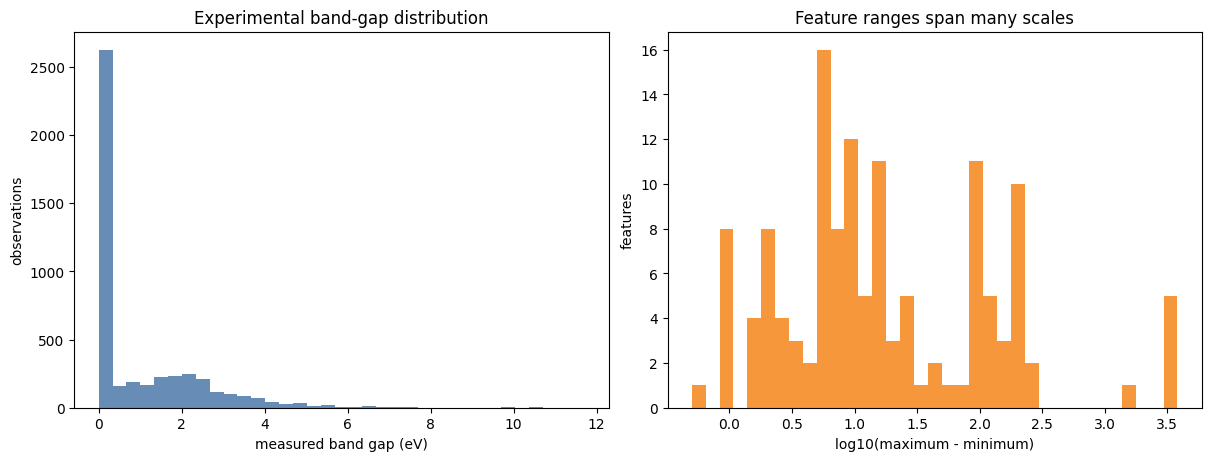

In [18]:
df = pd.read_csv(DATA_PATH)
target_candidates = [
    name for name in df.columns
    if 'gap' in name.lower()
    and any(token in name.lower() for token in ('expt', 'experiment', 'target'))
    and pd.api.types.is_numeric_dtype(df[name])
]
assert len(target_candidates) == 1, f'Ambiguous target candidates: {target_candidates}'
target_column = target_candidates[0]
compositions = df['composition'].astype(str)
feature_columns = list(METADATA['feature_columns'])
X = df[feature_columns].astype(float).copy()
y = df[target_column].astype(float).copy()
assert 'composition' not in X.columns and target_column not in X.columns
assert list(X.columns) == feature_columns
assert not X.isna().any().any() and not y.isna().any()
assert all(X[name].nunique() > 1 for name in X.columns)

inspection = pd.Series({
    'observations': len(df), 'raw columns': len(df.columns),
    'target': target_column, 'numeric model features': X.shape[1],
    'metadata excluded from model': 'composition',
    'missing numeric feature values': int(X.isna().sum().sum()),
}, name='dataset inspection')
display(inspection.to_frame())
display(pd.DataFrame({'composition': compositions.head(6), 'measured band gap (eV)': y.head(6)}))

feature_range = X.max() - X.min()
with plt.ioff():
    figure, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].hist(y, bins=35, color='#4c78a8', alpha=0.85)
axes[0].set(title='Experimental band-gap distribution', xlabel='measured band gap (eV)', ylabel='observations')
axes[1].hist(np.log10(feature_range[feature_range > 0]), bins=35, color='#f58518', alpha=0.85)
axes[1].set(title='Feature ranges span many scales', xlabel='log10(maximum - minimum)', ylabel='features')
display(figure); plt.close(figure)

## 4. Random Forest Regression, Ensemble Size, and Feature Budgets

An individual tree partitions feature space into regions with similar target values. A Random Forest averages many bootstrap-and-feature-subsampled trees. The first plot checks whether that ensemble average has stabilized before feature representation becomes the experimental variable.

The primary investigation fixes one representative forest configuration for every representation. Requested feature fractions are translated into integer counts with a documented minimum; both requested and actual counts remain in the cache.

### Framing Questions

- Has the ensemble average stabilized enough that feature representation, rather than forest size, is the main experimental variable?

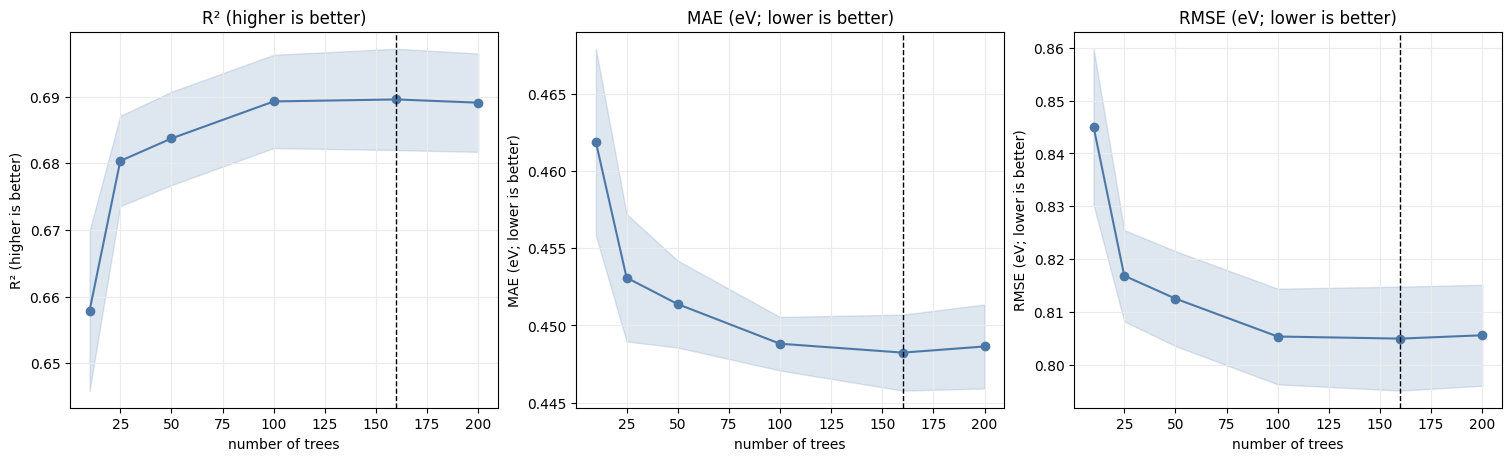

,representation,requested_fraction,requested_count,actual_count,cached_outer_experiments
0,All features,1.00,132,132,50
1,Correlation pruning,1.00,132,132,50
2,Correlation pruning,0.75,99,99,50
3,Correlation pruning,0.50,66,66,50
4,Correlation pruning,0.25,33,33,50
5,Correlation pruning,0.10,14,14,50
6,Correlation → permutation,1.00,132,132,50
7,Correlation → permutation,0.75,99,99,50
8,Correlation → permutation,0.50,66,66,50
9,Correlation → permutation,0.25,33,33,50


All primary analyses fix n_estimators = 160 and RF random_state = 2024.


In [19]:
convergence = query('SELECT * FROM convergence_results ORDER BY n_estimators, cv_seed')
fixed_trees = int(METADATA['config']['n_estimators'])
with plt.ioff():
    figure, axes = plt.subplots(1, 3, figsize=(15, 4.5), constrained_layout=True)
for axis, metric in zip(axes, ['r2', 'mae', 'rmse']):
    grouped = convergence.groupby('n_estimators')[metric]
    mean, spread = grouped.mean(), grouped.std().fillna(0)
    axis.plot(mean.index, mean, marker='o', color='#4c78a8')
    axis.fill_between(mean.index, mean-spread, mean+spread, color='#4c78a8', alpha=0.18)
    axis.axvline(fixed_trees, color='black', linestyle='--', linewidth=1)
    axis.set(xlabel='number of trees', ylabel=METRIC_LABELS[metric], title=METRIC_LABELS[metric])
    axis.grid(color='0.92')
display(figure); plt.close(figure)

representation_counts = query(
    '''SELECT strategy, requested_fraction, requested_count, actual_count, COUNT(*) AS cached_outer_experiments
       FROM outer_experiments WHERE workflow='primary'
       GROUP BY strategy, requested_fraction, requested_count, actual_count
       ORDER BY strategy, requested_fraction DESC'''
)
representation_counts['representation'] = representation_counts.strategy.map(STRATEGY_LABELS)
display(representation_counts[['representation', 'requested_fraction', 'requested_count', 'actual_count', 'cached_outer_experiments']])
print(f'All primary analyses fix n_estimators = {fixed_trees} and RF random_state = {METADATA["rf_seed"]}.')

## 5. Cross-Validation Splitters

We compare two kinds of evidence:

- **Shuffled K-fold** holds out randomly mixed observations and is mainly interpolation-like.
- **Feature-space LOCO** standardizes the numeric feature matrix only for KMeans, forms coherent regions in the full feature space, and holds out one region at a time. Forests still train on raw features.

The PCA coordinates below are for visualization only. KMeans used every standardized descriptor, and composition entered neither operation. Cluster construction saw the complete feature distribution, so LOCO remains a pedagogical generalization stress test—not an unbiased deployment estimate.

### Framing Questions

- What kind of generalization does each splitter test, and which one is closer to the intended use of the model?
- Do the held-out LOCO clusters expose regions of descriptor space that shuffled K-fold mixes into its training folds?

In [20]:
cluster_options = query('SELECT DISTINCT cv_seed, cluster_count FROM cluster_assignments ORDER BY cluster_count, cv_seed')
cluster_count_widget = SelectionSlider(options=sorted(cluster_options.cluster_count.unique()), value=int(cluster_options.cluster_count.min()), description='clusters', continuous_update=False)
cluster_seed_widget = Dropdown(options=sorted(cluster_options.cv_seed.unique()), value=int(cluster_options.cv_seed.min()), description='CV seed')

def render_clusters(cluster_count, cv_seed):
    points = query(
        '''SELECT c.*, o.composition, o.observed_target
           FROM cluster_assignments c JOIN observations o USING(observation_id)
           WHERE c.cluster_count=? AND c.cv_seed=? ORDER BY c.observation_id''',
        (int(cluster_count), int(cv_seed)),
    )
    with plt.ioff():
        figure, axis = plt.subplots(figsize=(8, 5.5), constrained_layout=True)
    scatter = axis.scatter(points.pc1, points.pc2, c=points.cluster_id, cmap='tab10', s=15, alpha=0.65)
    axis.set(title=f'Full-space KMeans groups shown in a 2-D PCA projection ({cluster_count} clusters)', xlabel='principal component 1', ylabel='principal component 2')
    figure.colorbar(scatter, ax=axis, label='held-out LOCO cluster')
    display(figure); plt.close(figure)
    examples = points.sort_values(['cluster_id', 'observed_target'], ascending=[True, False]).groupby('cluster_id', as_index=False).head(3)
    display(examples[['cluster_id', 'composition', 'observed_target']].round({'observed_target': 3}))

cluster_output = interactive_output(render_clusters, {'cluster_count': cluster_count_widget, 'cv_seed': cluster_seed_widget})
display(VBox([HBox([cluster_count_widget, cluster_seed_widget]), cluster_output]))

## 6. Feature Selection Within the Train–Validation Split

Feature selection is part of model fitting. Computing a correlation matrix or supervised ranking on the full dataset and then cross-validating the reduced matrix is an invalid workflow because outer-validation observations have influenced the representation. That workflow is discussed here but never computed.

The implemented workflow keeps each outer validation fold untouched. Correlation pruning uses outer-training predictors only. Permutation selection fits on inner-development folds and measures signed importance on inner-held-out folds. Correlation → permutation first removes redundancy, then asks which survivors supply held-out predictive evidence. The final forest is fitted on the complete outer-training set and evaluated once on the outer fold. Choose a cached run below and press **Load Selection Audit** to inspect its boundaries and evidence.

### Framing Questions

- Correlated features can distribute importance across multiple descriptors. Is this expected behavior? Why would using permutation feature importance to drop features behave differently?
- How would selecting features before the outer split leak information and make the downstream results look more trustworthy than they are?

In [21]:
selection_options = query(
    '''SELECT DISTINCT strategy, requested_fraction FROM selection_runs
       WHERE workflow='primary' AND strategy!='all' ORDER BY strategy, requested_fraction DESC'''
)
selection_choice_widget = Dropdown(
    options=[(f'{STRATEGY_LABELS[r.strategy]} | requested {r.requested_fraction:.0%}', (r.strategy, float(r.requested_fraction))) for r in selection_options.itertuples()],
    value=('correlation_permutation', float(METADATA['config']['representative_budget'])), description='representation',
)
selection_validation_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')

def render_selection_audit(representation, validation):
    strategy, budget = representation
    run = query(
        '''SELECT * FROM selection_runs WHERE workflow='primary' AND cv_method=?
           AND strategy=? AND ABS(requested_fraction-?)<1e-12
           ORDER BY cv_seed, outer_fold LIMIT 1''', (validation, strategy, budget),
    ).iloc[0]
    boundaries = query('SELECT * FROM inner_fold_boundaries WHERE selection_run_id=? ORDER BY inner_fold', (int(run.selection_run_id),))
    selected = query('SELECT feature_name, selection_rank, model_position FROM selected_features WHERE selection_run_id=? ORDER BY selection_rank', (int(run.selection_run_id),))
    pruning = query('SELECT * FROM correlation_pruning_evidence WHERE selection_run_id=? ORDER BY pruning_step', (int(run.selection_run_id),))
    permutation = query('SELECT feature_name, AVG(signed_importance) AS mean_importance, MIN(signed_importance) AS minimum, MAX(signed_importance) AS maximum FROM permutation_importance_evidence WHERE selection_run_id=? GROUP BY feature_name ORDER BY mean_importance DESC', (int(run.selection_run_id),))
    display(pd.Series({
        'validation strategy': CV_LABELS[validation], 'outer CV seed': int(run.cv_seed),
        'outer fold': int(run.outer_fold), 'requested budget': f'{budget:.0%}',
        'requested count': int(run.requested_count), 'actual retained count': int(run.actual_count),
        'outer-training hash': run.development_hash, 'untouched outer-fold hash': run.outer_validation_hash,
    }, name='one auditable nested selection run').to_frame())
    if not boundaries.empty:
        display(boundaries[['inner_fold', 'development_count', 'validation_count', 'development_hash', 'validation_hash']])
    display(selected.head(15))
    if not pruning.empty:
        display(pruning[['pruning_step', 'removed_feature', 'surviving_partner', 'absolute_pair_correlation']].head(12).round(4))
    if not permutation.empty:
        display(permutation.head(12).round(5))
        print(f'Negative signed inner-validation importance values retained: {(permutation.minimum < 0).sum()} features in this run.')

selection_audit_button = Button(description='Load Selection Audit', button_style='primary', icon='database')
selection_audit_output = Output()

def load_selection_audit(_button=None):
    with selection_audit_output:
        clear_output(wait=True)
        render_selection_audit(selection_choice_widget.value, selection_validation_widget.value)

selection_audit_button.on_click(load_selection_audit)
display(VBox([HBox([selection_choice_widget, selection_validation_widget]), selection_audit_button, selection_audit_output]))

## 7. Compound Prediction Trajectories During Feature Removal

This section asks: **For a compound that the full model predicts reasonably well, how does its prediction evolve as this particular feature-selection method progressively removes information?**

For each validation method and feature-selection strategy, the notebook selects five representative compounds **once across the complete 100%, 75%, 50%, 25%, and 10% budget trajectory**. It ranks compounds by their maximum seed-averaged absolute movement from the all-feature prediction over that trajectory, with lower all-feature baseline MAE as a secondary preference. It does not reselect compounds at each budget or construct a weighted score.

Every selected-feature prediction is paired to its all-feature counterpart for the same compound, CV seed, and outer fold before values are averaged across seeds. Shuffled K-fold and Feature-space LOCO have separate representative sets, tables, and interactive trajectory plots. The full database supplies all five budgets; the smoke fallback displays only its available cached budgets and never retrains a model.

### Framing Questions

- Find a compound that is predicted reasonably well by the full-feature model but whose prediction moves substantially as features are removed. Is the global model score hiding a locally important failure?
- A model can retain nearly the same RMSE while individual predictions move substantially. Which observation would concern you more if you were using the model to select a material for an experiment?

In [22]:
FEATURE_BUDGETS = [1.0, 0.75, 0.5, 0.25, 0.1]
trajectory_strategies = query(
    "SELECT DISTINCT strategy FROM outer_experiments WHERE workflow='primary' AND strategy!='all' ORDER BY strategy"
)
trajectory_strategy_widget = Dropdown(
    options=[(STRATEGY_LABELS[strategy], strategy) for strategy in trajectory_strategies.strategy],
    value='correlation_permutation', description='selection',
)
load_trajectory_button = Button(description='Load Trajectories', button_style='primary', icon='database')
trajectory_table_outputs = {method: Output() for method in ['kfold', 'loco']}
trajectory_plot_outputs = {method: Output() for method in ['kfold', 'loco']}
trajectory_compound_widgets = {
    'kfold': Dropdown(description='K-fold compound'),
    'loco': Dropdown(description='LOCO compound'),
}
TRAJECTORY_STATE = {}

def render_compound_trajectory(method):
    if method not in TRAJECTORY_STATE or trajectory_compound_widgets[method].value is None:
        return
    observation_id = int(trajectory_compound_widgets[method].value)
    compound = (
        TRAJECTORY_STATE[method]['trajectory']
        .loc[lambda values: values.observation_id == observation_id]
        .sort_values('requested_fraction', ascending=False)
    )
    composition = compound.composition.iloc[0]
    observed_target = compound.observed_target.iloc[0]
    all_feature_prediction = compound.mean_all_feature_prediction.iloc[0]
    with trajectory_plot_outputs[method]:
        clear_output(wait=True)
        with plt.ioff():
            figure, axis = plt.subplots(figsize=(8, 4.8), constrained_layout=True)
        axis.plot(
            100 * compound.requested_fraction, compound.mean_selected_feature_prediction,
            marker='o', linewidth=2, color=COLORS[method], label=STRATEGY_LABELS[TRAJECTORY_STATE['strategy']],
        )
        axis.axhline(observed_target, color='black', linewidth=1.5, label='observed target')
        axis.axhline(all_feature_prediction, color='#e45756', linestyle='--', linewidth=1.5, label='all-feature prediction')
        axis.set_xticks([100 * budget for budget in FEATURE_BUDGETS])
        axis.invert_xaxis()
        axis.set(
            xlabel='% features retained (progressive removal →)', ylabel='mean OOF prediction (eV)',
            title=f'{CV_LABELS[method]} | {composition}',
        )
        axis.grid(color='0.92'); axis.legend()
        display(figure); plt.close(figure)

def load_feature_trajectories(_button=None):
    strategy = trajectory_strategy_widget.value
    trajectory = query(
        '''WITH paired_predictions AS (
               SELECT selected.cv_method, selected.requested_fraction, selected.cv_seed, selected.outer_fold,
                      selected_prediction.observation_id, o.composition, o.observed_target,
                      baseline_prediction.y_pred AS all_feature_prediction,
                      selected_prediction.y_pred AS selected_feature_prediction
               FROM outer_experiments selected
               JOIN generalizability_predictions selected_prediction
                 ON selected_prediction.experiment_id=selected.experiment_id
               JOIN outer_experiments baseline
                 ON baseline.workflow=selected.workflow
                AND baseline.cv_method=selected.cv_method
                AND baseline.cv_seed=selected.cv_seed
                AND baseline.fold_count=selected.fold_count
                AND baseline.outer_fold=selected.outer_fold
                AND baseline.strategy='all'
                AND ABS(baseline.requested_fraction-1.0)<1e-12
               JOIN generalizability_predictions baseline_prediction
                 ON baseline_prediction.experiment_id=baseline.experiment_id
                AND baseline_prediction.observation_id=selected_prediction.observation_id
                AND baseline_prediction.outer_fold=selected_prediction.outer_fold
               JOIN observations o ON o.observation_id=selected_prediction.observation_id
               WHERE selected.workflow='primary' AND selected.strategy=?
           )
           SELECT cv_method, requested_fraction, observation_id, composition, observed_target,
                  AVG(all_feature_prediction) AS mean_all_feature_prediction,
                  AVG(selected_feature_prediction) AS mean_selected_feature_prediction,
                  AVG(ABS(all_feature_prediction-observed_target)) AS baseline_mae,
                  AVG(ABS(selected_feature_prediction-all_feature_prediction)) AS selection_movement
           FROM paired_predictions
           GROUP BY cv_method, requested_fraction, observation_id, composition, observed_target
           ORDER BY cv_method, observation_id, requested_fraction DESC''',
        (strategy,),
    )
    TRAJECTORY_STATE.clear()
    TRAJECTORY_STATE['strategy'] = strategy
    for method in ['kfold', 'loco']:
        method_trajectory = trajectory[trajectory.cv_method == method].copy()
        ranking = (
            method_trajectory.groupby(['observation_id', 'composition', 'observed_target'], as_index=False)
            .agg(
                mean_all_feature_prediction=('mean_all_feature_prediction', 'first'),
                baseline_mae=('baseline_mae', 'first'),
                full_trajectory_movement=('selection_movement', 'max'),
            )
            .sort_values(
                ['full_trajectory_movement', 'baseline_mae', 'composition', 'observation_id'],
                ascending=[False, True, True, True], kind='mergesort',
            )
            .head(5).copy()
        )
        selected_ids = ranking.observation_id.astype(int).tolist()
        table = ranking[['observation_id', 'composition', 'observed_target', 'mean_all_feature_prediction']].copy()
        for budget in FEATURE_BUDGETS:
            budget_predictions = (
                method_trajectory[np.isclose(method_trajectory.requested_fraction, budget)]
                .set_index('observation_id').mean_selected_feature_prediction
            )
            table[f'prediction at {budget:.0%}'] = table.observation_id.map(budget_predictions)
        table = table.drop(columns='observation_id').rename(columns={
            'observed_target': 'observed target',
            'mean_all_feature_prediction': 'all-feature prediction',
        })
        TRAJECTORY_STATE[method] = {'trajectory': method_trajectory, 'ranking': ranking}
        with trajectory_table_outputs[method]:
            clear_output(wait=True)
            print(f'{CV_LABELS[method]} | fixed representatives for {STRATEGY_LABELS[strategy]}')
            display(table.round(3))
        options = [
            (f'{row.composition} | observed {row.observed_target:.3f} eV', int(row.observation_id))
            for row in ranking.itertuples(index=False)
        ]
        trajectory_compound_widgets[method].options = options
        trajectory_compound_widgets[method].value = selected_ids[0]
        render_compound_trajectory(method)

def update_kfold_trajectory(change):
    if change['name'] == 'value' and change['new'] is not None:
        render_compound_trajectory('kfold')

def update_loco_trajectory(change):
    if change['name'] == 'value' and change['new'] is not None:
        render_compound_trajectory('loco')

load_trajectory_button.on_click(load_feature_trajectories)
trajectory_compound_widgets['kfold'].observe(update_kfold_trajectory, names='value')
trajectory_compound_widgets['loco'].observe(update_loco_trajectory, names='value')
display(VBox([
    HBox([trajectory_strategy_widget, load_trajectory_button]),
    trajectory_table_outputs['kfold'], trajectory_compound_widgets['kfold'], trajectory_plot_outputs['kfold'],
    trajectory_table_outputs['loco'], trajectory_compound_widgets['loco'], trajectory_plot_outputs['loco'],
]))
load_feature_trajectories()

## 8. Exploring GIFTERS: Generalizability

The left panel shows mean pooled-OOF performance against the **actual** retained count. The right panel shows paired change from the all-feature result on the same CV seed. For MAE and RMSE, lower is better; for R², higher is better. Ask whether there is a broad plateau, whether LOCO deteriorates sooner, and whether partition sensitivity changes as the representation becomes smaller.

Feature-space LOCO remains an OOD-like teaching stress test. Good shuffled K-fold evidence does not guarantee performance in a held-out descriptor region.

The main curves keep the forest configuration fixed to isolate representation effects. A FULL_PRECOMPUTE cache also reports the separately labelled sensitivity question: do conclusions change when each representation receives properly nested tuning inside the outer-training data? Smoke mode deliberately omits that expensive secondary workflow.

### Framing Questions

- Why do you think correlation-based feature reduction shows an earlier degradation in model performance?
- At what point does reducing the number of features meaningfully hurt performance, and does that conclusion change depending on whether you look at absolute \(R^2\) or the paired change from the all-feature model? (e.g. look at the first table)

In [23]:
validation_summary = query("SELECT * FROM generalizability_summary WHERE workflow='primary'")

generalization_cv_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')
generalization_metric_widget = Dropdown(options=[(METRIC_LABELS[k], k) for k in ['r2', 'mae', 'rmse']], value='rmse', description='metric')

def render_generalizability(validation, metric):
    current = validation_summary[validation_summary.cv_method == validation].copy()
    grouped = current.groupby(['strategy', 'actual_count'])[metric].agg(['mean', 'std']).reset_index()
    baseline = current[current.strategy == 'all'][['cv_seed', metric]].rename(columns={metric: 'baseline'})
    paired = current.merge(baseline, on='cv_seed'); paired['change'] = paired[metric] - paired.baseline
    with plt.ioff():
        figure, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    for strategy, group in grouped.groupby('strategy'):
        axes[0].plot(group.actual_count, group['mean'], marker='o', color=STRATEGY_COLORS[strategy], label=STRATEGY_LABELS[strategy])
    axes[0].set(xlabel='actual retained features', ylabel=METRIC_LABELS[metric], title='Mean pooled OOF evidence across CV seeds')
    axes[0].grid(color='0.92'); axes[0].legend()
    for strategy, group in paired[paired.strategy != 'all'].groupby('strategy'):
        curve = group.groupby('actual_count').change.agg(['mean', 'std']).reset_index()
        axes[1].errorbar(curve.actual_count, curve['mean'], yerr=curve['std'].fillna(0), marker='o', color=STRATEGY_COLORS[strategy], label=STRATEGY_LABELS[strategy])
    axes[1].axhline(0, color='black', linestyle='--', linewidth=1)
    axes[1].set(xlabel='actual retained features', ylabel=f'paired change in {METRIC_LABELS[metric]}', title='Change from all features on the same CV seed')
    axes[1].grid(color='0.92'); axes[1].legend()
    figure.suptitle(CV_LABELS[validation])
    display(figure); plt.close(figure)
    display(grouped.rename(columns={'std': 'across-CV-seed standard deviation'}).round(4))

    tuned = query("SELECT * FROM generalizability_summary WHERE workflow='tuned' AND cv_method=?", (validation,))
    if not tuned.empty:
        primary_sensitivity = current[current.requested_fraction.isin(tuned.requested_fraction.unique())]
        primary_means = primary_sensitivity.groupby(['strategy', 'requested_fraction', 'actual_count'])[metric].mean().rename('fixed forest')
        tuned_means = tuned.groupby(['strategy', 'requested_fraction', 'actual_count'])[metric].mean().rename('nested tuning')
        sensitivity = pd.concat([primary_means, tuned_means], axis=1).reset_index()
        sensitivity['nested tuning − fixed forest'] = sensitivity['nested tuning'] - sensitivity['fixed forest']
        sensitivity['representation'] = sensitivity.strategy.map(STRATEGY_LABELS)
        print('Secondary sensitivity question — kept separate from the fixed-forest comparison')
        display(sensitivity[['representation', 'requested_fraction', 'actual_count', 'fixed forest', 'nested tuning', 'nested tuning − fixed forest']].round(4))

generalization_output = interactive_output(render_generalizability, {'validation': generalization_cv_widget, 'metric': generalization_metric_widget})
display(VBox([HBox([generalization_cv_widget, generalization_metric_widget]), generalization_output]))

## 9. Interpretability / Explainability

A Random Forest has no single coefficient vector, and using fewer inputs does **not** make it intrinsically interpretable. Here feature pruning contributes only at the representation level: fewer variables may be easier to inspect, lower redundancy may simplify the scientific story, and repeated selection may reveal whether that story is consistent.

Selection frequency and Jaccard overlap describe representation stability. Outer-fold permutation importance is separate post-hoc explanatory evidence. Correlated descriptors can divide or substitute for one another, so neither membership nor importance is a measure of true causal relevance.

### Framing Questions

- Can two feature-selection strategies have nearly identical predictive performance while relying on substantially different descriptors? What does that imply about how much you should trust a single feature-importance explanation?
- When selected features change across folds, is the explanation describing a stable scientific relationship or one interchangeable predictive representation among several?

The final tables answer this question with one common metric: mean post-hoc outer-validation permutation importance. Within each CV method and strategy, all retained features are ranked by that mean importance. The displayed rows are the union of each strategy's top 10. They are ordered first by how many strategies place the feature in their top 10, then by how many strategies retained it, mean rank, and best rank. An em dash means that the strategy did not retain the feature.

In [24]:
interpret_options = query(
    '''SELECT DISTINCT e.strategy, e.requested_fraction
       FROM outer_experiments e JOIN posthoc_permutation_evidence p USING(experiment_id)
       WHERE e.workflow='primary' ORDER BY e.strategy, e.requested_fraction DESC'''
)
interpret_representation_widget = Dropdown(
    options=[(f'{STRATEGY_LABELS[r.strategy]} | requested {r.requested_fraction:.0%}', (r.strategy, float(r.requested_fraction))) for r in interpret_options.itertuples()],
    value=('correlation_permutation', float(METADATA['config']['representative_budget'])), description='representation',
)
interpret_cv_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')
interpret_top_widget = IntSlider(min=5, max=20, value=12, description='top features', continuous_update=False)

def render_interpretability(representation, validation, top_n):
    strategy, budget = representation
    frequency = query(
        '''SELECT s.feature_name, COUNT(*) AS selected_runs
           FROM selected_features s JOIN selection_runs r USING(selection_run_id)
           WHERE r.workflow='primary' AND r.cv_method=? AND r.strategy=?
             AND ABS(r.requested_fraction-?)<1e-12 GROUP BY s.feature_name''',
        (validation, strategy, budget),
    )
    run_count = query("SELECT COUNT(*) AS n FROM selection_runs WHERE workflow='primary' AND cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12", (validation, strategy, budget)).n.iloc[0]
    frequency['selection_frequency'] = frequency.selected_runs / run_count
    posthoc = query(
        '''SELECT p.feature_name, AVG(p.signed_importance) AS held_out_importance
           FROM posthoc_permutation_evidence p JOIN outer_experiments e USING(experiment_id)
           WHERE e.workflow='primary' AND e.cv_method=? AND e.strategy=?
             AND ABS(e.requested_fraction-?)<1e-12 GROUP BY p.feature_name''',
        (validation, strategy, budget),
    )
    combined = frequency.merge(posthoc, on='feature_name', how='outer').set_index('feature_name')
    combined['selection_frequency'] = combined.selection_frequency.fillna(0)
    names = set(combined.nlargest(top_n, 'selection_frequency').index) | set(combined.nlargest(top_n, 'held_out_importance').index)
    shown = combined.loc[list(names)].sort_values('selection_frequency')
    with plt.ioff():
        figure, axes = plt.subplots(1, 2, figsize=(15, max(6, 0.35*len(shown))), constrained_layout=True)
    positions = np.arange(len(shown))
    axes[0].barh(positions, shown.selection_frequency, color=STRATEGY_COLORS[strategy])
    axes[0].set(yticks=positions, yticklabels=shown.index, xlim=(0, 1), xlabel='selection frequency', title='Representation consistency')
    axes[1].barh(positions, shown.held_out_importance, color='#4c78a8')
    axes[1].set(yticks=positions, yticklabels=shown.index, xlabel='increase in RMSE after permutation (eV)', title='Post-hoc importance when selected')
    figure.suptitle(f'{STRATEGY_LABELS[strategy]} | requested {budget:.0%} | {CV_LABELS[validation]}')
    display(figure); plt.close(figure)
    overlap = query('SELECT jaccard, inclusion_changes, rank_spearman FROM stability_selection_results WHERE cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12', (validation, strategy, budget))
    display(pd.Series({
        'requested budget': f'{budget:.0%}', 'mean selected features': frequency.selection_frequency.sum(),
        'mean pairwise Jaccard': overlap.jaccard.mean(),
        'mean inclusion/exclusion changes': overlap.inclusion_changes.mean(),
        'mean permutation-rank Spearman': overlap.rank_spearman.mean(),
        'post-hoc scope': 'representative CV seed; conditional on selection',
    }, name='representation-level evidence').to_frame().round(4))


interpret_output = interactive_output(render_interpretability, {'representation': interpret_representation_widget, 'validation': interpret_cv_widget, 'top_n': interpret_top_widget})
display(VBox([HBox([interpret_representation_widget, interpret_cv_widget, interpret_top_widget]), interpret_output]))

RANKING_STRATEGIES = ['correlation', 'permutation', 'correlation_permutation']
REPRESENTATIVE_BUDGET = float(METADATA['config']['representative_budget'])

def build_posthoc_ranking_comparison(validation):
    posthoc_rankings = query(
        '''SELECT e.strategy, p.feature_name, AVG(p.signed_importance) AS mean_held_out_importance
           FROM posthoc_permutation_evidence p JOIN outer_experiments e USING(experiment_id)
           WHERE e.workflow='primary' AND e.cv_method=?
             AND e.strategy IN ('correlation', 'permutation', 'correlation_permutation')
             AND ABS(e.requested_fraction-?)<1e-12
           GROUP BY e.strategy, p.feature_name''',
        (validation, REPRESENTATIVE_BUDGET),
    )
    ranked_parts = []
    top_features = set()
    for strategy in RANKING_STRATEGIES:
        ranked = (
            posthoc_rankings[posthoc_rankings.strategy == strategy]
            .sort_values(['mean_held_out_importance', 'feature_name'], ascending=[False, True], kind='mergesort')
            .reset_index(drop=True)
        )
        ranked['rank'] = np.arange(1, len(ranked) + 1)
        top_features.update(ranked.head(10).feature_name)
        ranked_parts.append(ranked[['strategy', 'feature_name', 'rank']])

    comparison = (
        pd.concat(ranked_parts, ignore_index=True)
        .pivot(index='feature_name', columns='strategy', values='rank')
        .reindex(columns=RANKING_STRATEGIES)
        .loc[sorted(top_features)]
    )
    comparison.columns = [f'{strategy}_rank' for strategy in comparison.columns]
    rank_columns = list(comparison.columns)
    comparison['_top_10_count'] = comparison[rank_columns].le(10).sum(axis=1)
    comparison['_retained_count'] = comparison[rank_columns].notna().sum(axis=1)
    comparison['_mean_rank'] = comparison[rank_columns].mean(axis=1)
    comparison['_best_rank'] = comparison[rank_columns].min(axis=1)
    comparison = (
        comparison.reset_index(names='feature')
        .sort_values(
            ['_top_10_count', '_retained_count', '_mean_rank', '_best_rank', 'feature'],
            ascending=[False, False, True, True, True], kind='mergesort',
        )
    )
    for column in rank_columns:
        comparison[column] = comparison[column].map(lambda value: '—' if pd.isna(value) else str(int(value)))
    return comparison[['feature', *rank_columns]].reset_index(drop=True)

print('Post-hoc outer-validation permutation-importance rankings across selection strategies')
for validation in ['kfold', 'loco']:
    print(f'\n{CV_LABELS[validation]} | representative requested budget {REPRESENTATIVE_BUDGET:.0%}')
    display(build_posthoc_ranking_comparison(validation))

Post-hoc outer-validation permutation-importance rankings across selection strategies

Shuffled K-fold | representative requested budget 50%


,feature,correlation_rank,permutation_rank,correlation_permutation_rank
0,MagpieData mode SpaceGroupNumber,1,9,8
1,MagpieData avg_dev Electronegativity,4,7,7
2,MagpieData minimum GSvolume_pa,9,4,5
3,MagpieData range NdValence,14,2,4
4,MagpieData avg_dev GSbandgap,3,30,9
5,MagpieData mean NpValence,—,1,1
6,MagpieData mean MeltingT,—,3,2
7,MagpieData mean NpUnfilled,6,11,13
8,MagpieData avg_dev NpValence,10,19,17
9,MagpieData avg_dev MendeleevNumber,8,18,21



Feature-space LOCO | representative requested budget 50%


,feature,correlation_rank,permutation_rank,correlation_permutation_rank
0,MagpieData mean NpValence,2,1,1
1,MagpieData range NdUnfilled,3,5,5
2,MagpieData avg_dev Column,5,9,6
3,MagpieData mean NUnfilled,11,2,7
4,MagpieData mean SpaceGroupNumber,1,13,9
5,MagpieData mean NdUnfilled,29,7,4
6,MagpieData avg_dev GSbandgap,7,31,8
7,MagpieData mean MeltingT,42,6,3
8,MagpieData mean AtomicWeight,63,3,2
9,MagpieData mean NValence,18,14,10


## 10. Robustness

### 10.1 Performance Under Controlled Feature and Target Perturbations

Robustness asks what happens when we perturb the **data**. For each outer split, one standardized feature-noise direction and one target-noise direction are reused across the full crossed magnitude grid and across representations. Scales come only from the training fold; outer-validation inputs and clean targets remain unchanged.

Frozen representation asks whether a chosen feature set protects the fitted model. Rerun selection asks whether the selection decision itself changes under noisy training evidence. Every plotted value is paired to the zero-noise result from the **same CV seed and outer fold**. The panels report descriptive mean and across-split variability in that paired change; overlapping folds are not independent experiments.

### Framing Questions

- Is one method of feature selection more robust to noise in its ranking of important features?
- Which method of feature selection is least robust to noise?
- Compare frozen representation with rerun selection. If rerunning feature selection under noise produces much larger changes than keeping the representation fixed, where is the fragility actually coming from: the Random Forest or the feature-selection procedure?

In [25]:
robustness = query('SELECT * FROM robustness_results')
robust_options = robustness[['strategy', 'requested_fraction']].drop_duplicates().sort_values(['strategy', 'requested_fraction'])
robust_representation_widget = Dropdown(options=[(f'{STRATEGY_LABELS[r.strategy]} | requested {r.requested_fraction:.0%}', (r.strategy, float(r.requested_fraction))) for r in robust_options.itertuples(index=False)], value=('all', 1.0), description='representation')
robust_cv_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')
robust_process_widget = Dropdown(options=[(PROCESS_LABELS[k], k) for k in ['frozen_representation', 'rerun_selection']], value='frozen_representation', description='selection')
robust_metric_widget = Dropdown(options=[(METRIC_LABELS[k], k) for k in ['r2', 'mae', 'rmse']], value='rmse', description='metric')

def render_robustness_performance(representation, validation, process, metric):
    strategy, budget = representation
    current = robustness[(robustness.cv_method == validation) & (robustness.strategy == strategy) & np.isclose(robustness.requested_fraction, budget) & (robustness.process == process)]
    baseline = current[(current.feature_noise == 0) & (current.target_noise == 0)][['cv_seed', 'outer_fold', metric]].rename(columns={metric: 'zero_noise'})
    paired = current.merge(baseline, on=['cv_seed', 'outer_fold'], validate='many_to_one')
    paired['change'] = paired[metric] - paired.zero_noise
    grouped = paired.groupby(['target_noise', 'feature_noise']).change.agg(['mean', 'std']).reset_index()
    x_values = sorted(grouped.feature_noise.unique()); y_values = sorted(grouped.target_noise.unique())
    with plt.ioff():
        figure, axes = plt.subplots(1, 2, figsize=(14, 5.5), constrained_layout=True)
    for axis, statistic, title in zip(axes, ['mean', 'std'], ['Mean paired change from zero noise', 'Paired-change variability across splits']):
        matrix = grouped.pivot(index='target_noise', columns='feature_noise', values=statistic).reindex(index=y_values, columns=x_values).fillna(0).to_numpy()
        image = axis.imshow(matrix, origin='lower', aspect='auto', cmap='viridis')
        axis.set(xticks=np.arange(len(x_values)), xticklabels=x_values, yticks=np.arange(len(y_values)), yticklabels=y_values, xlabel='relative feature noise', ylabel='relative target noise', title=title)
        figure.colorbar(image, ax=axis, label=f'Δ {METRIC_LABELS[metric]}')
    figure.suptitle(f'{STRATEGY_LABELS[strategy]} | requested {budget:.0%} | {PROCESS_LABELS[process]} | {CV_LABELS[validation]}')
    display(figure); plt.close(figure)

robust_performance_output = interactive_output(render_robustness_performance, {'representation': robust_representation_widget, 'validation': robust_cv_widget, 'process': robust_process_widget, 'metric': robust_metric_widget})
display(VBox([HBox([robust_representation_widget, robust_cv_widget]), HBox([robust_process_widget, robust_metric_widget]), robust_performance_output]))

### 10.2 Do Selections, Explanations, and Individual Materials Change Too?

Predictive performance, the selected representation, and the explanatory story are different robustness claims. The next view tracks cached impurity importance for baseline-leading retained features over the crossed noise grid, reports how often features remain selected when selection is rerun, and lists materials with the largest clean-target errors at one chosen perturbation. Each feature heatmap uses its own labeled raw-importance scale spanning that feature's observed minimum and maximum because feature importances can differ substantially in magnitude.

A nearly flat performance surface can coexist with reordered feature evidence or unstable individual predictions. Return to the compositions and ask whether sensitive cases suggest chemistry, descriptor limitations, sparse feature-space coverage, or a data-quality question. Note that choosing **Permutation selection** changes the feature-selection procedure; the heatmaps below still show Random Forest mean-decrease-in-impurity importance, not post-hoc permutation importance.

In [26]:
robust_explain_representation_widget = Dropdown(options=robust_representation_widget.options, value=('correlation_permutation', float(METADATA['config']['representative_budget'])), description='representation')
robust_explain_cv_widget = Dropdown(options=robust_cv_widget.options, value='kfold', description='validation')
robust_explain_process_widget = Dropdown(options=robust_process_widget.options, value='rerun_selection', description='selection')
robust_top_widget = IntSlider(min=3, max=8, value=5, description='top features', continuous_update=False)
feature_noise_options = sorted(robustness.feature_noise.unique())
target_noise_options = sorted(robustness.target_noise.unique())
example_feature_noise_widget = SelectionSlider(options=feature_noise_options, value=feature_noise_options[-1], description='feature noise', continuous_update=False)
example_target_noise_widget = SelectionSlider(options=target_noise_options, value=target_noise_options[-1], description='target noise', continuous_update=False)

def render_robustness_explanations(representation, validation, process, top_n, feature_noise, target_noise):
    strategy, budget = representation
    values = query(
        '''WITH chosen_runs AS (
               SELECT robustness_id, feature_noise, target_noise FROM robustness_results
               WHERE cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12 AND process=?
           )
           SELECT r.feature_noise, r.target_noise, f.feature_name,
                  AVG(COALESCE(i.importance, 0.0)) AS importance
           FROM chosen_runs r CROSS JOIN features f
           LEFT JOIN robustness_importances i
             ON i.robustness_id=r.robustness_id AND i.feature_name=f.feature_name
           GROUP BY r.feature_noise, r.target_noise, f.feature_name''',
        (validation, strategy, budget, process),
    )
    baseline = values[(values.feature_noise == 0) & (values.target_noise == 0)].nlargest(top_n, 'importance').feature_name.tolist()
    n_columns = min(4, len(baseline))
    n_rows = int(np.ceil(len(baseline) / n_columns))
    with plt.ioff():
        figure, axes_grid = plt.subplots(
            n_rows, n_columns, figsize=(4.2*n_columns, 4.8*n_rows),
            squeeze=False, sharex=True, sharey=True, constrained_layout=True,
        )
    axes = axes_grid.ravel()
    for axis, feature in zip(axes, baseline):
        part = values[values.feature_name == feature]
        matrix = part.pivot(index='target_noise', columns='feature_noise', values='importance').reindex(index=target_noise_options, columns=feature_noise_options).fillna(0).to_numpy()
        panel_min = float(np.nanmin(matrix))
        panel_max = float(np.nanmax(matrix))
        if not np.isfinite(panel_min) or not np.isfinite(panel_max):
            panel_min, panel_max = 0.0, 1.0
        elif np.isclose(panel_min, panel_max):
            padding = max(abs(panel_min) * 0.05, 1e-12)
            panel_min -= padding
            panel_max += padding
        image = axis.imshow(
            matrix, origin='lower', aspect='auto', cmap='viridis',
            vmin=panel_min, vmax=panel_max,
        )
        axis.set(title=feature.replace('MagpieData ', '', 1)[:24], xticks=np.arange(len(feature_noise_options)), xticklabels=feature_noise_options, yticks=np.arange(len(target_noise_options)), yticklabels=target_noise_options, xlabel='feature noise')
        colorbar = figure.colorbar(image, ax=axis, fraction=0.046, pad=0.04)
        colorbar.set_label('mean impurity importance', fontsize=9)
        colorbar.ax.tick_params(labelsize=8)
    for axis in axes[len(baseline):]:
        axis.set_visible(False)
    axes[0].set_ylabel('target noise')
    figure.suptitle('Noise response of impurity importance (independent observed min–max per feature)')
    display(figure); plt.close(figure)
    selected = query(
        '''WITH chosen_runs AS (
               SELECT robustness_id FROM robustness_results
               WHERE cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12
                 AND process=? AND ABS(feature_noise-?)<1e-12 AND ABS(target_noise-?)<1e-12
           )
           SELECT f.feature_name,
                  AVG(CASE WHEN s.feature_name IS NULL THEN 0.0 ELSE 1.0 END) AS selection_frequency
           FROM features f CROSS JOIN chosen_runs r
           LEFT JOIN robustness_selected_features s
             ON s.robustness_id=r.robustness_id AND s.feature_name=f.feature_name
           GROUP BY f.feature_name ORDER BY selection_frequency DESC, f.feature_name''',
        (validation, strategy, budget, process, feature_noise, target_noise),
    )
    display(selected.head(12).round(3))
    examples = query(
        '''WITH chosen AS (
               SELECT r.cv_seed, r.outer_fold, p.observation_id, p.y_true, p.y_pred
               FROM robustness_results r JOIN robustness_predictions p USING(robustness_id)
               WHERE r.cv_method=? AND r.strategy=? AND ABS(r.requested_fraction-?)<1e-12
                 AND r.process=? AND ABS(r.feature_noise-?)<1e-12 AND ABS(r.target_noise-?)<1e-12
           ), zero_noise AS (
               SELECT r.cv_seed, r.outer_fold, p.observation_id, p.y_pred AS zero_noise_prediction
               FROM robustness_results r JOIN robustness_predictions p USING(robustness_id)
               WHERE r.cv_method=? AND r.strategy=? AND ABS(r.requested_fraction-?)<1e-12
                 AND r.process=? AND r.feature_noise=0 AND r.target_noise=0
           )
           SELECT o.composition, chosen.y_true, AVG(chosen.y_pred) AS mean_prediction,
                  AVG(ABS(chosen.y_pred-zero_noise.zero_noise_prediction)) AS mean_absolute_prediction_movement,
                  AVG(chosen.y_pred-zero_noise.zero_noise_prediction) AS mean_signed_prediction_movement,
                  AVG(ABS(chosen.y_pred-chosen.y_true)) AS mean_absolute_error
           FROM chosen JOIN zero_noise USING(cv_seed, outer_fold, observation_id)
           JOIN observations o USING(observation_id)
           GROUP BY chosen.observation_id
           ORDER BY mean_absolute_prediction_movement DESC LIMIT 10''',
        (validation, strategy, budget, process, feature_noise, target_noise,
         validation, strategy, budget, process),
    )
    print('Materials with the largest prediction movement from their paired zero-noise result')
    display(examples.round(3))

robust_explanation_output = interactive_output(render_robustness_explanations, {'representation': robust_explain_representation_widget, 'validation': robust_explain_cv_widget, 'process': robust_explain_process_widget, 'top_n': robust_top_widget, 'feature_noise': example_feature_noise_widget, 'target_noise': example_target_noise_widget})
display(VBox([HBox([robust_explain_representation_widget, robust_explain_cv_widget, robust_explain_process_widget]), HBox([robust_top_widget, example_feature_noise_widget, example_target_noise_widget]), robust_explanation_output]))

## 11. Exploring GIFTERS: Model Stability

In GIFTERS, **stability** asks whether a fitted model gives reasonably equivalent predictions after small changes to the model itself. This is deliberately different from robustness:

> **Section 10 asked:** What happens when I perturb the **data**?  
> **Section 11 asks:** What happens when I perturb the **fitted model**?

All experiments below are cached. The primary evidence is movement in material-level predictions; aggregate error remains useful, but nearly unchanged RMSE can conceal substantial movement for particular compositions.

### Framing Questions

- Which version of the models is most sensitive to changes in the tree thresholds?
- Does the feature-selection method that is most robust to noisy training data also produce the most stable model when tree weights or split thresholds are perturbed? Why are those not necessarily the same property?

### 11.1 Choose One Representation and Cached Forest Experiment

Choose a representation and validation strategy, then press **Load Cached Experiment**. The button performs SQL queries only. It selects the precomputed experiments generated with the fixed forest configuration, CV seed, outer folds, and paired perturbation seeds.

In [27]:
stability_results = query('SELECT * FROM stability_prediction_results')
stability_options = stability_results[['strategy', 'requested_fraction']].drop_duplicates().sort_values(['strategy', 'requested_fraction'])
stability_representation_widget = Dropdown(options=[(f'{STRATEGY_LABELS[r.strategy]} | requested {r.requested_fraction:.0%}', (r.strategy, float(r.requested_fraction))) for r in stability_options.itertuples(index=False)], value=('all', 1.0), description='representation')
stability_cv_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')
load_stability_button = Button(description='Load Cached Experiment', button_style='primary', icon='database')
stability_training_output = Output()
stability_refresh_widget = IntSlider(value=0, min=0, max=1_000_000, layout={'display': 'none'})
STABILITY_STATE = {'representation': ('all', 1.0), 'validation': 'kfold'}

def load_cached_stability(_button=None):
    STABILITY_STATE['representation'] = stability_representation_widget.value
    STABILITY_STATE['validation'] = stability_cv_widget.value
    strategy, budget = STABILITY_STATE['representation']
    current = stability_results[(stability_results.cv_method == STABILITY_STATE['validation']) & (stability_results.strategy == strategy) & np.isclose(stability_results.requested_fraction, budget)]
    with stability_training_output:
        clear_output(wait=True)
        display(pd.Series({
            'representation': STRATEGY_LABELS[strategy], 'requested budget': f'{budget:.0%}',
            'validation strategy': CV_LABELS[STABILITY_STATE['validation']],
            'cached outer folds': current.outer_fold.nunique(),
            'tree-reweighting magnitudes': current[current.mechanism == 'tree_reweighting'].magnitude.nunique(),
            'threshold magnitudes': current[current.mechanism == 'threshold'].magnitude.nunique(),
            'additional forest fits': 0,
        }, name='selected cached stability experiment').to_frame())

    stability_refresh_widget.value += 1

load_stability_button.on_click(load_cached_stability)
display(VBox([HBox([stability_representation_widget, stability_cv_widget]), load_stability_button, stability_training_output]))
load_cached_stability()

### 11.2 Tree-Reweighting Stability

The ordinary forest assigns every fitted tree weight $1/T$. We perturb only those relative weights:

$$z_t\sim\mathcal{N}(0,1),\qquad u_t=\exp(\sigma_w z_t),\qquad w_t=\frac{u_t}{\sum_j u_j}.$$

The effective tree count $N_{\mathrm{eff}}=1/\sum_t w_t^2$ equals $T$ for uniform weights and falls as fewer trees dominate. The generator reused the same weight draws across representations where mathematically possible.

In [28]:
weight_strengths = sorted(stability_results.loc[stability_results.mechanism == 'tree_reweighting', 'magnitude'].unique())
tree_weight_sigma_widget = SelectionSlider(options=weight_strengths, value=weight_strengths[0], description='weight σ', continuous_update=False)

def render_tree_weight_stability(magnitude, _refresh):
    strategy, budget = STABILITY_STATE['representation']
    validation = STABILITY_STATE['validation']
    conditions = query("SELECT * FROM stability_prediction_results WHERE mechanism='tree_reweighting' AND cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12 AND ABS(magnitude-?)<1e-12", (validation, strategy, budget, magnitude))
    ids = conditions.stability_id.astype(int).tolist()
    placeholders = ','.join('?' for _ in ids)
    realizations = query(f'SELECT * FROM stability_realizations WHERE stability_id IN ({placeholders})', ids)
    materials = query(f'''SELECT p.*, o.composition FROM stability_predictions p JOIN observations o USING(observation_id) WHERE p.stability_id IN ({placeholders})''', ids)
    sensitive = materials.nlargest(12, 'prediction_interval_width').sort_values('prediction_interval_width')
    with plt.ioff():
        figure, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)
    axes[0].hist(realizations.effective_tree_count.dropna(), bins=20, color='#4c78a8', alpha=0.85)
    axes[0].set(xlabel='effective tree count', ylabel='perturbed ensembles', title='Ensemble concentration')
    axes[1].hist(realizations.rmse, bins=20, color='#54a24b', alpha=0.85)
    axes[1].axvline(conditions.baseline_rmse.mean(), color='black', linestyle='--', label='baseline')
    axes[1].set(xlabel='outer-validation RMSE (eV)', ylabel='perturbed ensembles', title='Aggregate performance'); axes[1].legend()
    positions = np.arange(len(sensitive))
    axes[2].hlines(positions, sensitive.prediction_lower_2_5, sensitive.prediction_upper_97_5, color='#4c78a8', linewidth=2)
    axes[2].scatter(sensitive.baseline_prediction, positions, marker='D', color='#e45756', label='baseline')
    axes[2].set(yticks=positions, yticklabels=sensitive.composition, xlabel='predicted band gap (eV)', title='Most weight-sensitive materials'); axes[2].legend()
    figure.suptitle(f'{STRATEGY_LABELS[strategy]} | {CV_LABELS[validation]} | tree-weight σ = {magnitude:g}')
    display(figure); plt.close(figure)
    condition_table = conditions[['outer_fold', 'median_effective_tree_count', 'median_absolute_prediction_movement', 'p95_absolute_prediction_movement', 'rmse_movement']].copy()
    condition_table['outer_fold'] += 1
    display(condition_table.rename(columns={'outer_fold': 'outer fold (1-based)'}).round(5))

tree_weight_output = interactive_output(render_tree_weight_stability, {'magnitude': tree_weight_sigma_widget, '_refresh': stability_refresh_widget})
display(VBox([tree_weight_sigma_widget, tree_weight_output]))

**Interrogate the evidence:** Does the RMSE distribution remain narrow while any material-level intervals become noticeable? How quickly does the effective tree count fall, and do the sensitive compositions suggest a region of chemistry that deserves closer scrutiny?

### 11.3 Internal-Threshold Stability

Every internal tree node asks whether $x_j\leq\tau$. The cached experiment moves eligible learned boundaries without changing the input data, topology, or leaf predictions:

$$\tau'=\tau+\epsilon z s_{\mathrm{node},j},\qquad z\sim\mathcal{N}(0,1).$$

The node-local scale is an IQR with a standard-deviation fallback; thresholds are clamped to the node's observed training range. To keep this perturbation local and comparable, only nodes through the configured maximum depth are eligible; that cached value is shown in the figure title. Zero perturbation is asserted to reproduce sklearn predictions and terminal leaves exactly.

In [29]:
threshold_strengths = sorted(stability_results.loc[stability_results.mechanism == 'threshold', 'magnitude'].unique())
threshold_epsilon_widget = SelectionSlider(options=threshold_strengths, value=threshold_strengths[0], description='threshold ε', continuous_update=False)

def render_threshold_stability(magnitude, _refresh):
    strategy, budget = STABILITY_STATE['representation']
    validation = STABILITY_STATE['validation']
    conditions = query("SELECT * FROM stability_prediction_results WHERE mechanism='threshold' AND cv_method=? AND strategy=? AND ABS(requested_fraction-?)<1e-12 AND ABS(magnitude-?)<1e-12", (validation, strategy, budget, magnitude))
    ids = conditions.stability_id.astype(int).tolist(); placeholders = ','.join('?' for _ in ids)
    realizations = query(f'SELECT * FROM stability_realizations WHERE stability_id IN ({placeholders})', ids)
    materials = query(f'''SELECT p.*, o.composition FROM stability_predictions p JOIN observations o USING(observation_id) WHERE p.stability_id IN ({placeholders})''', ids)
    sensitive = materials.nlargest(12, 'prediction_interval_width').sort_values('prediction_interval_width')
    with plt.ioff():
        figure, axes = plt.subplots(2, 2, figsize=(16, 10), constrained_layout=True)
    axes[0, 0].hist(realizations.rmse, bins=20, color='#54a24b', alpha=0.85)
    axes[0, 0].axvline(conditions.baseline_rmse.mean(), color='black', linestyle='--', label='baseline')
    axes[0, 0].set(xlabel='outer-validation RMSE (eV)', ylabel='perturbed forests', title='Aggregate performance'); axes[0, 0].legend()
    axes[0, 1].hist(realizations.mean_routing_change.dropna(), bins=20, color='#f58518', alpha=0.85)
    axes[0, 1].set(xlabel='mean changed-path fraction', ylabel='perturbation realizations', title='Per-realization routing change')
    positions = np.arange(len(sensitive))
    axes[1, 0].hlines(positions, sensitive.prediction_lower_2_5, sensitive.prediction_upper_97_5, color='#4c78a8', linewidth=2)
    axes[1, 0].scatter(sensitive.baseline_prediction, positions, marker='D', color='#e45756', label='baseline')
    axes[1, 0].set(yticks=positions, yticklabels=sensitive.composition, xlabel='predicted band gap (eV)', title='Most threshold-sensitive materials'); axes[1, 0].legend()
    axes[1, 1].hist(materials.mean_routing_change.dropna(), bins=20, color='#f58518', alpha=0.85)
    axes[1, 1].set(xlabel='fraction of trees reaching a different leaf', ylabel='materials', title='Material-level mean routing sensitivity')
    maximum_depth = int(METADATA['config']['stability_threshold_max_depth'])
    figure.suptitle(f'{STRATEGY_LABELS[strategy]} | {CV_LABELS[validation]} | threshold ε = {magnitude:g} | perturbed depth ≤ {maximum_depth}')
    display(figure); plt.close(figure)
    condition_table = conditions[['outer_fold', 'mean_routing_change', 'median_absolute_prediction_movement', 'p95_absolute_prediction_movement', 'rmse_movement']].copy()
    condition_table['outer_fold'] += 1
    display(condition_table.rename(columns={'outer_fold': 'outer fold (1-based)'}).round(5))

threshold_output = interactive_output(render_threshold_stability, {'magnitude': threshold_epsilon_widget, '_refresh': stability_refresh_widget})
display(VBox([threshold_epsilon_widget, threshold_output]))

**Interrogate the evidence:** Follow the chain from threshold movement to changed routing and changed ensemble prediction. Can routing change while aggregate RMSE stays nearly constant? Are routing-sensitive materials also prediction-sensitive?

### 11.4 Stability Curves

Detailed views show one perturbation setting at a time. The summary below sweeps every cached tree-weight and threshold magnitude for all four representations. Solid and dashed curves show the 95th percentile and median absolute prediction movement; median RMSE change remains secondary evidence. Threshold curves retain the same configured maximum perturbation depth used above. No fitting occurs.

In [30]:
stability_curve_cv_widget = Dropdown(options=[(CV_LABELS[k], k) for k in ['kfold', 'loco']], value='kfold', description='validation')

def render_stability_curves(validation):
    current = stability_results[stability_results.cv_method == validation]
    grouped = current.groupby(['mechanism', 'strategy', 'requested_fraction', 'magnitude'])[['median_absolute_prediction_movement', 'p95_absolute_prediction_movement', 'rmse_movement']].mean().reset_index()
    with plt.ioff():
        figure, axes = plt.subplots(2, 2, figsize=(14, 9), sharey='row', constrained_layout=True)
    for column, mechanism in enumerate(['tree_reweighting', 'threshold']):
        part = grouped[grouped.mechanism == mechanism]
        for (strategy, budget), group in part.groupby(['strategy', 'requested_fraction']):
            label = f'{STRATEGY_LABELS[strategy]} ({budget:.0%})'
            axes[0, column].plot(group.magnitude, group.p95_absolute_prediction_movement, marker='o', color=STRATEGY_COLORS[strategy], label=f'{label} — 95th percentile')
            axes[0, column].plot(group.magnitude, group.median_absolute_prediction_movement, marker='.', linestyle='--', color=STRATEGY_COLORS[strategy], label=f'{label} — median')
            axes[1, column].plot(group.magnitude, group.rmse_movement, marker='o', color=STRATEGY_COLORS[strategy])
        mechanism_title = mechanism.replace('_', ' ').title()
        if mechanism == 'threshold':
            mechanism_title += f" (depth ≤ {METADATA['config']['stability_threshold_max_depth']})"
        axes[0, column].set(xlabel='perturbation magnitude', ylabel='absolute prediction movement (eV)', title=mechanism_title)
        axes[1, column].axhline(0, color='black', linestyle='--', linewidth=1)
        axes[1, column].set(xlabel='perturbation magnitude', ylabel='median ΔRMSE (eV)')
        axes[0, column].grid(color='0.92'); axes[1, column].grid(color='0.92')
    axes[0, 0].legend(fontsize=7, ncol=2)
    figure.suptitle(f'Cached model-perturbation curves | {CV_LABELS[validation]}')
    display(figure); plt.close(figure)
    display(grouped.round(6))

stability_curves_output = interactive_output(render_stability_curves, {'validation': stability_curve_cv_widget})
display(VBox([stability_curve_cv_widget, stability_curves_output]))

## 12. Summary and Synthesis

Use the linked evidence to build a qualified claim rather than naming one universally best representation. Summarize what the notebook shows about generalizability, interpretability / explainability, robustness, and stability, and keep aggregate performance separate from material-level behavior.

### Final Synthesis Prompt

You are given only the final RMSE of the best-performing model. Based on everything else in this notebook, what important information about trustworthiness would be missing? Cite at least three pieces of evidence from different sections.

A strong summary should connect evidence about:

- shuffled K-fold versus feature-space LOCO;
- the performance plateau and the point where pruning begins to hurt;
- retained descriptors and the stability of feature-importance explanations;
- frozen versus rerun selection under noisy training data; and
- aggregate RMSE versus movement in individual material predictions under feature removal or model perturbation.

> **Fewer features can make a representation easier to inspect, but they do not make a Random Forest intrinsically interpretable. Stable aggregate error does not guarantee stable individual predictions.**

Generalizability, Interpretability / Explainability, Robustness, and Stability remain separate claims expressed in different units. No mathematically justified scalar GIFTERS score is defined here. Every view is traceable to cached rows with documented dataset, configuration, seed, and software provenance.